In [ ]:
# STEP 1.1 — session setup (run this first in EVERY new Colab session)
import os, sys, random, zipfile, hashlib
import numpy as np, pandas as pd, torch, transformers, PIL
from google.colab import drive, files
drive.mount("/content/drive")

PROJ = "/content/mars_compression"
for f in ["splits", "checkpoints/segformer_v1", "results", "figures", "logs"]:
    os.makedirs(f"{PROJ}/{f}", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def save_to_laptop(paths, zip_name):
    out = f"/content/{zip_name}.zip"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in paths:
            if not os.path.exists(p):
                print("Skipping missing path:", p); continue
            if os.path.isdir(p):
                for r, _, fs in os.walk(p):
                    for f in fs:
                        full = os.path.join(r, f); zf.write(full, os.path.relpath(full, PROJ))
            else:
                zf.write(p, os.path.relpath(p, PROJ) if p.startswith(PROJ) else os.path.basename(p))
    print("Created:", out, "| Size:", round(os.path.getsize(out) / 2**20, 2), "MB")
    files.download(out)

print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__)
print("numpy", np.__version__, "| PIL", PIL.__version__, "| pandas", pd.__version__)
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then rerun."
print("GPU:", torch.cuda.get_device_name(0), "|", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1), "GB")

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | transformers 5.22.1
numpy 2.4.6 | PIL 11.3.0 | pandas 2.2.3
GPU: Tesla T4 | 14.6 GB


In [ ]:
# STEP 1.2 — copy the dataset from your Drive cache into this session, verify it, and spot-check files
import os, zipfile, hashlib, numpy as np, pandas as pd
from PIL import Image

ZIP_DIR = "/content/drive/MyDrive/mars_dataset_zips"      # the 4 dataset zips live here (one-time upload)
DATA    = "/content/dataset_v3_512"
EXPECTED_MD5 = {
    "dataset_v3_512_train_part1.zip":   "472c16dfb062924339e9af591e302cf6",
    "dataset_v3_512_train_part2.zip":   "de4d82423da2f87f9c6b97f42e1499c9",
    "dataset_v3_512_train_part3.zip":   "e7b9ea4f5090e8fc73a749a1a2155f65",
    "dataset_v3_512_val_test_csv.zip":  "d322e616e764d58ba0053ae86c506232",
}
EXPECTED_N = {"train": 9803, "val": 1192, "test_msl": 311, "test_mer": 195}

assert os.path.isdir(ZIP_DIR), f"Folder not found: {ZIP_DIR}  (upload the 4 zips to that Drive folder first)"
def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for ch in iter(lambda: f.read(1 << 24), b""): h.update(ch)
    return h.hexdigest()

for name, exp in EXPECTED_MD5.items():
    p = f"{ZIP_DIR}/{name}"
    assert os.path.exists(p), f"Missing in Drive: {name}"
    got = md5(p); assert got == exp, f"CORRUPT/CHANGED ZIP {name}: {got}"
    zipfile.ZipFile(p).extractall("/content")
    print("extracted OK:", name)

rows = []
rng = np.random.RandomState(0)
for sp, n in EXPECTED_N.items():
    d = pd.read_csv(f"{DATA}/{sp}.csv")
    ni, nm = len(os.listdir(f"{DATA}/{sp}/img")), len(os.listdir(f"{DATA}/{sp}/mask"))
    assert len(d) == n and ni == n and nm == n, (sp, len(d), ni, nm)
    vals = set()
    for i in rng.choice(len(d), min(60, len(d)), replace=False):
        im, mk = Image.open(f"{DATA}/{d.img_512[i]}"), Image.open(f"{DATA}/{d.mask_512[i]}")
        assert im.size == (512, 512) and im.mode == "L" and mk.size == (512, 512), (sp, i)
        vals |= set(np.unique(np.array(mk)).tolist())
    assert vals <= {0, 1, 2, 3, 255}, vals
    rows.append(dict(split=sp, csv_rows=len(d), img_files=ni, mask_files=nm, mask_values_seen=sorted(vals)))
print("\nDATASET READY"); print(pd.DataFrame(rows).to_string(index=False))

extracted OK: dataset_v3_512_train_part1.zip
extracted OK: dataset_v3_512_train_part2.zip
extracted OK: dataset_v3_512_train_part3.zip
extracted OK: dataset_v3_512_val_test_csv.zip

DATASET READY
   split  csv_rows  img_files  mask_files  mask_values_seen
   train      9803       9803        9803 [0, 1, 2, 3, 255]
     val      1192       1192        1192 [0, 1, 2, 3, 255]
test_msl       311        311         311 [0, 1, 2, 3, 255]
test_mer       195        195         195 [0, 1, 2, 3, 255]


In [ ]:
# SECTION 0.3 — Set up persistent project storage on Google Drive

import os
import shutil

OLD_PROJ = "/content/mars_compression"
PROJ = "/content/drive/MyDrive/mars_compression"

# Preserve anything already created in the temporary directory
if os.path.isdir(OLD_PROJ):
    shutil.copytree(OLD_PROJ, PROJ, dirs_exist_ok=True)

# Create all project directories on Drive
folders = [
    "splits",
    "checkpoints/segformer_v1",
    "results",
    "figures",
    "logs",
    "backups"
]

for folder in folders:
    os.makedirs(os.path.join(PROJ, folder), exist_ok=True)

print("PROJECT DIRECTORY:", PROJ)
print("\nPersistent folders:")

for folder in folders:
    path = os.path.join(PROJ, folder)
    print("✓", path, "| Exists:", os.path.isdir(path))

print("\nProject storage ready.")

PROJECT DIRECTORY: /content/drive/MyDrive/mars_compression

Persistent folders:
✓ /content/drive/MyDrive/mars_compression/splits | Exists: True
✓ /content/drive/MyDrive/mars_compression/checkpoints/segformer_v1 | Exists: True
✓ /content/drive/MyDrive/mars_compression/results | Exists: True
✓ /content/drive/MyDrive/mars_compression/figures | Exists: True
✓ /content/drive/MyDrive/mars_compression/logs | Exists: True
✓ /content/drive/MyDrive/mars_compression/backups | Exists: True

Project storage ready.


In [ ]:

# SECTION A1 — Dataset loader and DataLoaders

import os
import json
import random
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

DATA = "/content/dataset_v3_512"

CLASS_NAMES = ["soil", "bedrock", "sand", "big rock"]

# Verify the dataset directory
assert os.path.isdir(DATA), f"Dataset not found: {DATA}"

class MarsSeg(Dataset):

    def __init__(self, split, train=False, indices=None):
        self.d = pd.read_csv(f"{DATA}/{split}.csv")
        if indices is not None:
            self.d = self.d.iloc[list(indices)].reset_index(drop=True)

        self.train = train

        required = {"img_512", "mask_512"}
        assert required.issubset(self.d.columns), (
            f"Missing CSV columns: {required - set(self.d.columns)}"
        )

    def __len__(self):
        return len(self.d)

    def __getitem__(self, i):
        r = self.d.iloc[i]

        img_path = os.path.join(DATA, r.img_512)
        mask_path = os.path.join(DATA, r.mask_512)

        img = np.array(Image.open(img_path).convert("L"), dtype=np.uint8)
        msk = np.array(Image.open(mask_path), dtype=np.uint8)

        assert img.shape == (512, 512), img_path
        assert msk.shape == (512, 512), mask_path

        # Horizontal flip: apply identically to image and mask
        if self.train and torch.rand(1).item() < 0.5:
            img = np.fliplr(img)
            msk = np.fliplr(msk)

        x = torch.from_numpy(
            np.ascontiguousarray(img)
        ).float().div_(255.0).unsqueeze(0)

        y = torch.from_numpy(
            np.ascontiguousarray(msk)
        ).long()

        return x, y


def make_loaders(bs=8, seed=42, workers=2):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        MarsSeg("train", train=True),
        batch_size=bs,
        shuffle=True,
        drop_last=True,
        num_workers=workers,
        pin_memory=True,
        generator=generator,
        persistent_workers=workers > 0
    )

    val_loader = DataLoader(
        MarsSeg("val"),
        batch_size=16,
        shuffle=False,
        num_workers=workers,
        pin_memory=True
    )

    return train_loader, val_loader


# Fixed training evaluation subset
subset_path = f"{PROJ}/logs/train_eval_subset_idx.json"

if os.path.exists(subset_path):
    with open(subset_path) as f:
        TRAIN_EVAL_IDX = json.load(f)
else:
    n_train = len(pd.read_csv(f"{DATA}/train.csv"))

    TRAIN_EVAL_IDX = sorted(
        np.random.RandomState(0).choice(
            n_train, min(1000, n_train), replace=False
        ).tolist()
    )

    with open(subset_path, "w") as f:
        json.dump(TRAIN_EVAL_IDX, f)

assert len(TRAIN_EVAL_IDX) == 1000

# Create loaders
train_loader, val_loader = make_loaders()

print("Train images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Fixed train evaluation subset:", len(TRAIN_EVAL_IDX))

print("\nDataset loader created successfully.")


Train images: 9803
Validation images: 1192
Fixed train evaluation subset: 1000

Dataset loader created successfully.


train     paths OK | missing files: 0 | image/mask name mismatches: 0
val       paths OK | missing files: 0 | image/mask name mismatches: 0
test_msl  paths OK | missing files: 0 | image/mask name mismatches: 0
test_mer  paths OK | missing files: 0 | image/mask name mismatches: 0

batch x: (8, 1, 512, 512) torch.float32 range [0.01, 0.99]
batch y: (8, 512, 512) torch.int64 labels present: [0, 1, 2, 3, 255]
batch class share: {'soil': 0.291, 'bedrock': 0.545, 'sand': 0.143, 'big rock': 0.021} | ignored px: 37.8%
loader speed: 0.056 s per batch of 8  ->  loading alone would take about 1.1 min/epoch


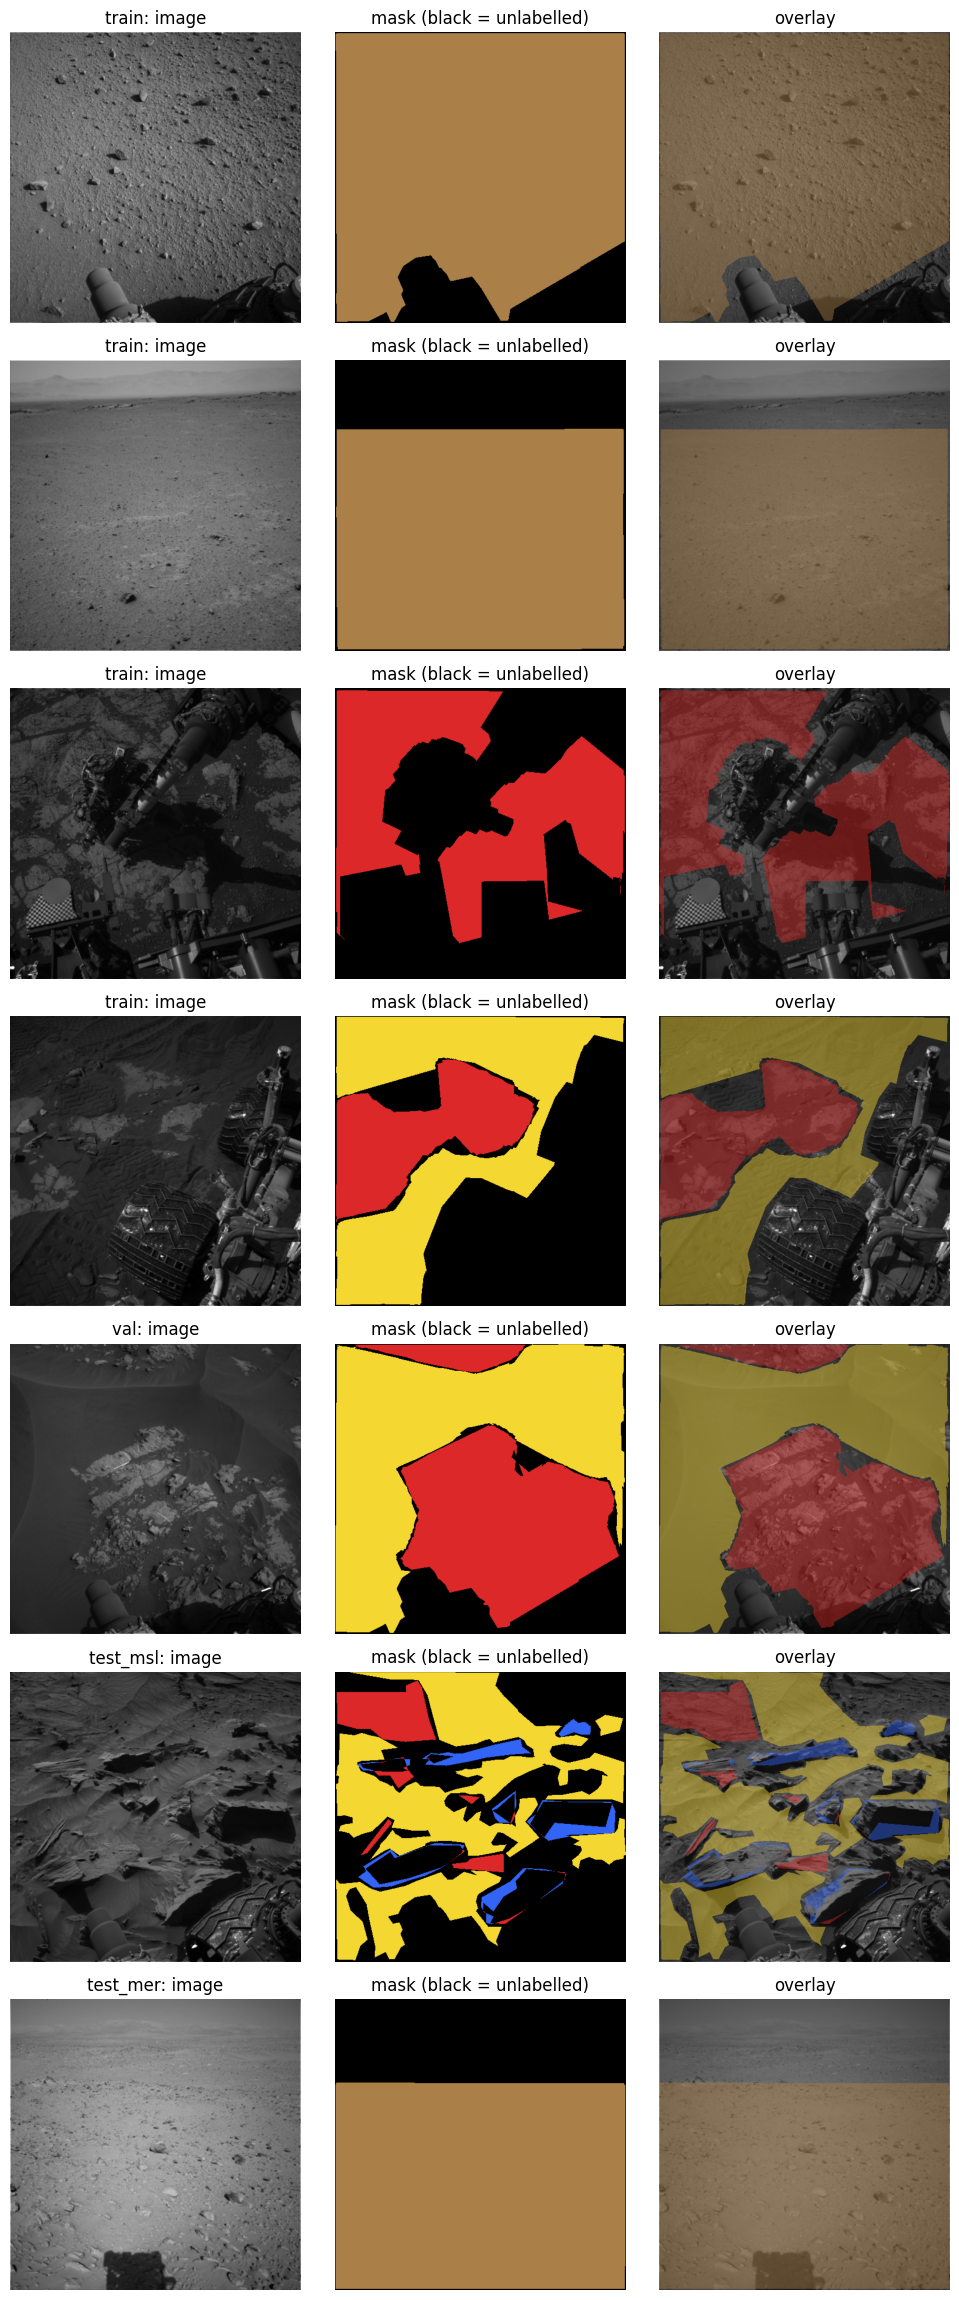

Legend: tan = soil, red = bedrock, yellow = sand, blue = big rock, black = unlabelled (ignored)


In [ ]:
# STEP 2b — helpers + checks + visual alignment (run AFTER Cell 4; reuses its MarsSeg / loaders)
import os, sys, time, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, transformers, PIL

COLORS = {0: (170, 128, 72), 1: (220, 40, 40), 2: (245, 215, 50), 3: (50, 100, 245)}   # tan, red, yellow, blue

def overlay(img_u8, mask, alpha=0.45):
    """img_u8: HxW uint8 gray; mask: HxW (classes 0-3 are tinted, everything else untouched). Returns HxWx3 uint8."""
    rgb = np.stack([img_u8] * 3, -1).astype(np.float32)
    for c, col in COLORS.items():
        m = mask == c; rgb[m] = (1 - alpha) * rgb[m] + alpha * np.array(col, dtype=np.float32)
    return rgb.astype(np.uint8)

with open(f"{PROJ}/logs/environment.txt", "w") as f:                       # reproducibility record
    f.write(f"python {sys.version.split()[0]}\ntorch {torch.__version__}\ntransformers {transformers.__version__}\n"
            f"numpy {np.__version__}\nPIL {PIL.__version__}\npandas {pd.__version__}\n")

# 1) every CSV path resolves, and each image is paired with the mask of the SAME name
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
for sp in ["train", "val", "test_msl", "test_mer"]:
    d = pd.read_csv(f"{DATA}/{sp}.csv")
    missing = sum(not os.path.exists(f"{DATA}/{p}") for p in list(d.img_512) + list(d.mask_512))
    mismatched = sum(stem(a) != stem(b) for a, b in zip(d.img_512, d.mask_512))
    assert missing == 0 and mismatched == 0, (sp, missing, mismatched)
    print(f"{sp:9s} paths OK | missing files: {missing} | image/mask name mismatches: {mismatched}")

# 2) one real training batch
set_seed(42)
x, y = next(iter(train_loader))
print("\nbatch x:", tuple(x.shape), x.dtype, f"range [{x.min():.2f}, {x.max():.2f}]")
print("batch y:", tuple(y.shape), y.dtype, "labels present:", sorted(torch.unique(y).tolist()))
valid = y[y != 255]
print("batch class share:", {n: round(float((valid == i).float().mean()), 3) for i, n in enumerate(CLASS_NAMES)},
      "| ignored px:", f"{float((y == 255).float().mean()):.1%}")

# 3) loader speed (includes worker start-up, so it slightly overestimates)
t0 = time.time(); n = 0
for xb, yb in train_loader:
    n += 1
    if n == 40: break
dt = (time.time() - t0) / n
print(f"loader speed: {dt:.3f} s per batch of 8  ->  loading alone would take about {dt * len(train_loader) / 60:.1f} min/epoch")

# 4) visual check: 4 train (augmented) + 1 val + 1 MSL test + 1 MER test
rows = []
vs = MarsSeg("train", train=True)
for i in np.random.RandomState(1).choice(len(vs), 4, replace=False): rows.append(("train", vs[i]))
for sp in ["val", "test_msl", "test_mer"]:
    ds = MarsSeg(sp); rows.append((sp, ds[int(np.random.RandomState(2).randint(len(ds)))]))
fig, ax = plt.subplots(len(rows), 3, figsize=(10, 3.3 * len(rows)))
for r, (name, (xi, yi)) in enumerate(rows):
    im = (xi[0].numpy() * 255).astype(np.uint8); m = yi.numpy()
    ax[r, 0].imshow(im, cmap="gray"); ax[r, 0].set_title(f"{name}: image")
    mk = np.zeros((*m.shape, 3), np.uint8)
    for c, col in COLORS.items(): mk[m == c] = col
    ax[r, 1].imshow(mk); ax[r, 1].set_title("mask (black = unlabelled)")
    ax[r, 2].imshow(overlay(im, m)); ax[r, 2].set_title("overlay")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/step2_alignment_check.png", dpi=80); plt.show()
print("Legend: tan = soil, red = bedrock, yellow = sand, blue = big rock, black = unlabelled (ignored)")

In [ ]:
# STEP 3a — model wrapper, loss, evaluator, and sanity tests (nothing here is the "real" training)
import json, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation, SegformerConfig

DEV, PRETRAINED = "cuda", "nvidia/mit-b0"
USE_AMP, AMP_DT = (DEV == "cuda"), torch.float16
MEAN, STD = 0.449, 0.226            # grayscale equivalents of the ImageNet statistics (same as your legacy model)

class SegWrap(nn.Module):
    """Input: B x 1 x H x W float in [0,1]. Output: B x 4 x H x W logits (upsampled to the input size).
    Normalisation and the 3-channel repeat happen HERE, so JPEG2000/codec reconstructions can be fed in as plain [0,1] images."""
    def __init__(self, pretrained=PRETRAINED):
        super().__init__()
        id2label = {i: n for i, n in enumerate(CLASS_NAMES)}; label2id = {n: i for i, n in id2label.items()}
        if pretrained:
            self.net = SegformerForSemanticSegmentation.from_pretrained(pretrained, num_labels=4, id2label=id2label, label2id=label2id)
        else:
            self.net = SegformerForSemanticSegmentation(SegformerConfig(num_labels=4, id2label=id2label, label2id=label2id))
    def forward(self, x):
        h, w = x.shape[-2:]
        x = ((x - MEAN) / STD).repeat(1, 3, 1, 1)
        return F.interpolate(self.net(pixel_values=x).logits, size=(h, w), mode="bilinear", align_corners=False)

def new_model(): return SegWrap().to(DEV)

def metrics_from_conf(conf, loss=None):
    """conf[i, j] = pixels with true class i predicted as class j (label 255 never enters)."""
    conf = np.asarray(conf, dtype=np.float64); tp = np.diag(conf); gt = conf.sum(1); pr = conf.sum(0); union = gt + pr - tp
    with np.errstate(divide="ignore", invalid="ignore"):
        iou  = np.where(union > 0, tp / union, np.nan);  rec  = np.where(gt > 0, tp / gt, np.nan)
        prec = np.where(pr > 0, tp / pr, np.nan);        dice = np.where(gt + pr > 0, 2 * tp / (gt + pr), np.nan)
    return dict(loss=loss, miou4=float(np.nanmean(iou)), miou3=float(np.nanmean(iou[:3])), pixacc=float(tp.sum() / conf.sum()),
                iou=iou.tolist(), recall=rec.tolist(), precision=prec.tolist(), dice=dice.tolist(), conf=conf.astype(np.int64).tolist())

@torch.no_grad()
def evaluate(model, loader, max_batches=None):
    model.eval(); conf = torch.zeros(16, dtype=torch.long, device=DEV); loss_sum, n_valid = 0.0, 0
    for b, (x, y) in enumerate(loader):
        if max_batches and b >= max_batches: break
        x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
        with torch.autocast(DEV, dtype=AMP_DT, enabled=USE_AMP): logits = model(x)
        logits = logits.float(); v = y != 255
        loss_sum += F.cross_entropy(logits, y, ignore_index=255, reduction="sum").item(); n_valid += int(v.sum())
        conf += torch.bincount(y[v] * 4 + logits.argmax(1)[v], minlength=16)
    return metrics_from_conf(conf.view(4, 4).cpu().numpy(), loss_sum / max(n_valid, 1))

def train_step(model, opt, scaler, x, y):
    model.train(); x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
    opt.zero_grad(set_to_none=True)
    with torch.autocast(DEV, dtype=AMP_DT, enabled=USE_AMP): logits = model(x)
    loss = F.cross_entropy(logits.float(), y, ignore_index=255)
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    gn = nn.utils.clip_grad_norm_(model.parameters(), 1e9)          # only MEASURES the norm (no real clipping)
    scaler.step(opt); scaler.update()
    return loss.item(), float(gn)

R = {}   # results saved at the end

# ---- T0: metric code on a hand-made confusion matrix (no model involved)
toy = [[8, 2, 0, 0], [1, 9, 0, 0], [0, 0, 5, 0], [0, 0, 0, 0]]
m = metrics_from_conf(toy)
assert abs(m["iou"][0] - 8 / 11) < 1e-9 and abs(m["iou"][1] - 0.75) < 1e-9 and m["iou"][2] == 1.0 and np.isnan(m["iou"][3])
assert abs(m["pixacc"] - 22 / 25) < 1e-9 and abs(m["miou4"] - (8 / 11 + 0.75 + 1) / 3) < 1e-9
print("T0 metric code: PASS (matches hand-computed IoU / pixel accuracy)")

# ---- T1: model
set_seed(42); model = new_model()
n_par = sum(p.numel() for p in model.parameters())
R["params_M"] = round(n_par / 1e6, 3); R["hf_revision"] = str(getattr(model.net.config, "_commit_hash", None)); R["pretrained"] = PRETRAINED
print(f"T1 model: {R['params_M']} M parameters (expected 3.715) | pretrained={PRETRAINED} | HF revision={R['hf_revision']}")

# ---- T2: untrained head -> loss near ln(4)=1.386 and near-chance mIoU
ev = evaluate(model, val_loader, max_batches=10)
R["init_loss"], R["init_miou4"] = ev["loss"], ev["miou4"]
print(f"T2 untrained model on 160 val images: loss {ev['loss']:.3f} (ln 4 = 1.386) | mIoU4 {ev['miou4']:.3f} (should be low)")

# ---- T3: gradients reach both the pretrained encoder and the new head
x, y = next(iter(train_loader)); x, y = x.to(DEV), y.to(DEV)
model.train(); model.zero_grad()
with torch.autocast(DEV, dtype=AMP_DT, enabled=USE_AMP): lg = model(x)
F.cross_entropy(lg.float(), y, ignore_index=255).backward()
g = lambda key: float(torch.sqrt(sum((p.grad.float() ** 2).sum() for n_, p in model.named_parameters() if key in n_ and p.grad is not None)))
ge, gh = g("segformer."), g("decode_head.")
R["grad_encoder"], R["grad_head"] = ge, gh
print(f"T3 gradient norms: encoder {ge:.3f} | head {gh:.3f} | finite: {np.isfinite(ge) and np.isfinite(gh)}")
del model, lg; torch.cuda.empty_cache() if DEV == "cuda" else None

# ---- T4: real speed and memory with the real loader (20 training iterations)
set_seed(42); model = new_model(); opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
scaler = torch.amp.GradScaler(DEV, enabled=USE_AMP)
if DEV == "cuda": torch.cuda.reset_peak_memory_stats()
it = iter(train_loader); next_batches = [next(it) for _ in range(2)]            # warm-up
for xb, yb in next_batches: train_step(model, opt, scaler, xb, yb)
if DEV == "cuda": torch.cuda.synchronize()
t0 = time.time()
for _ in range(20):
    xb, yb = next(it); train_step(model, opt, scaler, xb, yb)
if DEV == "cuda": torch.cuda.synchronize()
spi = (time.time() - t0) / 20
t0 = time.time(); evaluate(model, val_loader, max_batches=10)
if DEV == "cuda": torch.cuda.synchronize()
spe = (time.time() - t0) / 160
peak = torch.cuda.max_memory_allocated() / 2**30 if DEV == "cuda" else float("nan")
steps_per_epoch = len(train_loader)
R.update(sec_per_iter=spi, peak_mem_gb=peak)
est_epoch = (spi * steps_per_epoch + spe * (len(val_loader.dataset) + 1000)) / 60
R["est_min_per_epoch"] = est_epoch
print(f"T4 speed: {spi:.3f} s/iteration (batch 8) | peak GPU memory {peak:.2f} GB | "
      f"estimated {est_epoch:.1f} min/epoch incl. evaluation -> 20 epochs ~ {20 * est_epoch:.0f} min")
del model, opt; torch.cuda.empty_cache() if DEV == "cuda" else None

# ---- T5: can it memorise 64 training images? (checks labels, loss and optimiser end to end; flips OFF)
set_seed(42)
N_OVER, STEPS = min(64, len(TRAIN_EVAL_IDX)), 200
ds = MarsSeg("train", train=False, indices=TRAIN_EVAL_IDX[:N_OVER])
X = torch.stack([ds[i][0] for i in range(N_OVER)]); Y = torch.stack([ds[i][1] for i in range(N_OVER)])
model = new_model(); opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.0)
scaler = torch.amp.GradScaler(DEV, enabled=USE_AMP); losses = []
bs = 8
for s in range(STEPS):
    idx = torch.randint(0, N_OVER, (min(bs, N_OVER),))
    l, _ = train_step(model, opt, scaler, X[idx], Y[idx]); losses.append(l)
    if (s + 1) % 50 == 0: print(f"   overfit step {s + 1:3d}: loss {np.mean(losses[-50:]):.3f}")
over_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, Y), batch_size=8)
ov = evaluate(model, over_loader)
R.update(overfit_final_loss=float(np.mean(losses[-20:])), overfit_miou4=ov["miou4"])
print(f"T5 memorise {N_OVER} images: final loss {R['overfit_final_loss']:.3f} | mIoU4 on them {ov['miou4']:.3f}")
del model, opt; torch.cuda.empty_cache() if DEV == "cuda" else None

# ---- verdict
ok = dict(init_loss=0.9 < R["init_loss"] < 2.5, grads=np.isfinite(ge) and np.isfinite(gh) and ge > 0 and gh > 0,
          memorise=(R["overfit_final_loss"] < 0.35 and R["overfit_miou4"] > 0.80), memory=(DEV != "cuda" or peak < 12))
R["checks"] = {k: bool(v) for k, v in ok.items()}
json.dump(R, open(f"{PROJ}/results/step3_sanity.json", "w"), indent=1)
print("\nCHECKS:", R["checks"]); print("ALL PASSED" if all(ok.values()) else "SOMETHING NEEDS A LOOK - send me this output")

T0 metric code: PASS (matches hand-computed IoU / pixel accuracy)


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

... (10 outputs left out)

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           

   overfit step  50: loss 0.523
   overfit step 100: loss 0.276
   overfit step 150: loss 0.158
   overfit step 200: loss 0.091
T5 memorise 64 images: final loss 0.075 | mIoU4 on them 0.724

CHECKS: {'init_loss': True, 'grads': True, 'memorise': False, 'memory': True}
SOMETHING NEEDS A LOOK - send me this output


In [ ]:
# STEP 3a-fix — memorisation test, longer, with per-class results + confusion matrix
import json, numpy as np, torch
names = ["soil", "bedrock", "sand", "big rock"]
if "ov" in globals():     # free: the snapshot from the 200-step run in Step 3a
    print("200-STEP SNAPSHOT (already computed in Step 3a): IoU =", [round(v, 2) for v in ov["iou"]],
          "| recall =", [round(v, 2) for v in ov["recall"]], "\n")
set_seed(42)
N_OVER, STEPS = 64, 500
ds = MarsSeg("train", train=False, indices=TRAIN_EVAL_IDX[:N_OVER])
X = torch.stack([ds[i][0] for i in range(N_OVER)]); Y = torch.stack([ds[i][1] for i in range(N_OVER)])
print("big-rock pixels in these 64 images:", int((Y == 3).sum()), "| images containing big rock:", int(((Y == 3).flatten(1).any(1)).sum()), "\n")

model = new_model(); opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.0)
scaler = torch.amp.GradScaler(DEV, enabled=USE_AMP); losses = []
over_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, Y), batch_size=8)
for s in range(STEPS):
    idx = torch.randint(0, N_OVER, (8,))
    l, _ = train_step(model, opt, scaler, X[idx], Y[idx]); losses.append(l)
    if (s + 1) % 100 == 0:
        ev = evaluate(model, over_loader)
        print(f"step {s + 1:3d}: loss {np.mean(losses[-100:]):.3f} | mIoU3 {ev['miou3']:.3f} | mIoU4 {ev['miou4']:.3f} | "
              f"IoU soil/bedrock/sand/bigrock = " + " / ".join(f"{v:.2f}" for v in ev["iou"]))
ev = evaluate(model, over_loader)
passed = bool(np.mean(losses[-20:]) < 0.15 and ev["miou3"] > 0.85)

cm = np.array(ev["conf"], dtype=float); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
print("\nCONFUSION at the end (rows = TRUE class, columns = PREDICTED; each row sums to 100%)")
print(" " * 10 + "".join(f"{n:>10s}" for n in names))
for i, n in enumerate(names): print(f"{n:>10s}" + "".join(f"{100 * v:9.1f}%" for v in cmn[i]))
print("\nrecall    (soil/bedrock/sand/bigrock):", [round(v, 3) for v in ev["recall"]])
print("precision (soil/bedrock/sand/bigrock):", [round(v, 3) for v in ev["precision"]])
print("pixel accuracy:", round(ev["pixacc"], 4), "| final loss:", round(float(np.mean(losses[-20:])), 4))

json.dump(dict(final_loss=float(np.mean(losses[-20:])), miou3=ev["miou3"], miou4=ev["miou4"], iou=ev["iou"],
               recall=ev["recall"], precision=ev["precision"], conf=ev["conf"], passed=passed),
          open(f"{PROJ}/results/step3_overfit_recheck.json", "w"), indent=1)
print("\nRECHECK:", "PASSED" if passed else "NOT PASSED - send me this output")
del model, opt; torch.cuda.empty_cache() if DEV == "cuda" else None

200-STEP SNAPSHOT (already computed in Step 3a): IoU = [0.99, 0.95, 0.95, 0.0] | recall = [0.99, 0.99, 0.98, 0.0] 



[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


big-rock pixels in these 64 images: 41614 | images containing big rock: 10 



Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           

step 100: loss 0.384 | mIoU3 0.658 | mIoU4 0.495 | IoU soil/bedrock/sand/bigrock = 0.82 / 0.82 / 0.34 / 0.01
step 200: loss 0.202 | mIoU3 0.898 | mIoU4 0.673 | IoU soil/bedrock/sand/bigrock = 0.96 / 0.91 / 0.82 / 0.00
step 300: loss 0.129 | mIoU3 0.920 | mIoU4 0.691 | IoU soil/bedrock/sand/bigrock = 0.97 / 0.96 / 0.82 / 0.01
step 400: loss 0.090 | mIoU3 0.728 | mIoU4 0.556 | IoU soil/bedrock/sand/bigrock = 0.72 / 0.52 / 0.94 / 0.04
step 500: loss 0.082 | mIoU3 0.987 | mIoU4 0.815 | IoU soil/bedrock/sand/bigrock = 0.99 / 0.98 / 0.99 / 0.30

CONFUSION at the end (rows = TRUE class, columns = PREDICTED; each row sums to 100%)
                soil   bedrock      sand  big rock
      soil     99.8%      0.2%      0.1%      0.0%
   bedrock      0.6%     99.4%      0.0%      0.0%
      sand      0.1%      0.3%     99.6%      0.0%
  big rock     20.5%     43.8%      5.7%     30.1%

recall    (soil/bedrock/sand/bigrock): [0.998, 0.994, 0.996, 0.301]
precision (soil/bedrock/sand/bigrock): [0.997

In [ ]:
# STEP 3b — pipeline validation with your LEGACY model (nothing here tunes the new model)
import json, os, numpy as np, torch
from torch.utils.data import DataLoader
from google.colab import files

if not os.path.exists("best_msl.pt"):
    print("Choose best_msl.pt from your laptop (mars-compression/checkpoints/legacy_epoch14/) ...")
    files.upload()
legacy = SegWrap(pretrained=None).to(DEV)
print(legacy.net.load_state_dict(torch.load("best_msl.pt", map_location=DEV)))     # must say: <All keys matched successfully>

REF = {   # numbers from your legacy baseline_results.csv (the ones I verified in the audit)
    "test_msl": dict(miou4=0.6742, miou3=0.8594, pixacc=0.9259, iou=[0.9139, 0.8134, 0.8508, 0.1186]),
    "test_mer": dict(miou4=0.6069, miou3=0.6957, pixacc=0.8248, iou=[0.7328, 0.7030, 0.6514, 0.3404]),
}
out = {}
for sp, ref in REF.items():
    r = evaluate(legacy, DataLoader(MarsSeg(sp), batch_size=16, shuffle=False, num_workers=2, pin_memory=True))
    d4 = r["miou4"] - ref["miou4"]
    out[sp] = dict(new_miou4=r["miou4"], new_miou3=r["miou3"], new_pixacc=r["pixacc"], new_iou=r["iou"], ref=ref, delta_miou4=d4)
    print(f"\n{sp}: mIoU4 new {r['miou4']:.4f} vs legacy {ref['miou4']:.4f} (diff {d4:+.4f}) | "
          f"mIoU3 {r['miou3']:.4f} vs {ref['miou3']:.4f} | pixel acc {r['pixacc']:.4f} vs {ref['pixacc']:.4f}")
    print("   IoU new   :", [round(v, 4) for v in r["iou"]])
    print("   IoU legacy:", ref["iou"])
ok = all(abs(v["delta_miou4"]) < 0.02 for v in out.values())
out["passed"] = bool(ok)
json.dump(out, open(f"{PROJ}/results/step3b_legacy_reproduction.json", "w"), indent=1)
print("\nREPRODUCTION:", "PASSED (within 0.02 mIoU4 on both sets)" if ok else "CHECK - send me this output")
del legacy; torch.cuda.empty_cache()

Choose best_msl.pt from your laptop (mars-compression/checkpoints/legacy_epoch14/) ...


Saving best_msl.pt to best_msl.pt
<All keys matched successfully>

test_msl: mIoU4 new 0.6741 vs legacy 0.6742 (diff -0.0001) | mIoU3 0.8602 vs 0.8594 | pixel acc 0.9262 vs 0.9259
   IoU new   : [0.914, 0.8142, 0.8525, 0.1158]
   IoU legacy: [0.9139, 0.8134, 0.8508, 0.1186]

test_mer: mIoU4 new 0.6079 vs legacy 0.6069 (diff +0.0010) | mIoU3 0.6969 vs 0.6957 | pixel acc 0.8256 vs 0.8248
   IoU new   : [0.7342, 0.7038, 0.6526, 0.3411]
   IoU legacy: [0.7328, 0.703, 0.6514, 0.3404]

REPRODUCTION: PASSED (within 0.02 mIoU4 on both sets)


In [ ]:
from pathlib import Path
import hashlib

PROJ = Path("/content/drive/MyDrive/mars_compression")

print("PROJECT EXISTS:", PROJ.exists())
print("\nIMPORTANT FILES:")

targets = [
    "results/step3b_legacy_reproduction.json",
    "logs/environment.txt",
    "logs/train_eval_subset_idx.json",
    "figures/step2_alignment_check.png",
    "checkpoints/segformer_v1",
    "splits",
    "results",
    "logs",
]

for item in targets:
    p = PROJ / item
    if p.is_file():
        print(f"FILE   | {item} | {p.stat().st_size:,} bytes")
    elif p.is_dir():
        contents = list(p.iterdir())
        print(f"FOLDER | {item} | {len(contents)} items")
    else:
        print(f"MISSING| {item}")

result = PROJ / "results/step3b_legacy_reproduction.json"
if result.exists():
    digest = hashlib.sha256(result.read_bytes()).hexdigest()
    print("\nLegacy reproduction SHA256:", digest)

PROJECT EXISTS: True

IMPORTANT FILES:
FILE   | results/step3b_legacy_reproduction.json | 850 bytes
FILE   | logs/environment.txt | 90 bytes
FILE   | logs/train_eval_subset_idx.json | 5,892 bytes
FILE   | figures/step2_alignment_check.png | 960,096 bytes
FOLDER | checkpoints/segformer_v1 | 0 items
FOLDER | splits | 0 items
FOLDER | results | 3 items
FOLDER | logs | 2 items

Legacy reproduction SHA256: 57bcf27c571d2fbd85e83477518e0808d521f6be1fdf4908e8d2e31b3734b997


In [ ]:
from google.colab import drive, runtime

drive.flush_and_unmount()
print("Google Drive unmounted. Releasing runtime...")
runtime.unassign()

Google Drive unmounted. Releasing runtime...
